**Analysis of M27**

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from astropy.io import fits
import os
from photutils.centroids import centroid_com, centroid_2dg  #load centroid libraries
from photutils.background import Background2D, MedianBackground
from photutils.aperture import CircularAperture
from astropy.stats import SigmaClip


In [2]:
#Master BIAS
if True:
    bias_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\bias\\"
    bias_files = os.listdir(bias_dir) #all files in directory
    bias_images = [] #array that contains all bias images

    for file in bias_files: #which datasets?
        image = fits.getdata(bias_dir+file)
        bias_images.append(image)

    # Stack the Bias images using median
    master_bias = np.median(np.asarray(bias_images), axis=0) #meridian is less sensitive to outliers

    #save the master bias as fits file

    savename = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\" + "master_bias.fits"
    fits.writeto(savename, master_bias, overwrite=True)

In [3]:
#Master FLATS
if True:
    flat_dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\flats"
    flat_folders = os.listdir(flat_dir) #all files in directory



    #different filters
    filters = ["black","red","green","blue"]
    master_flats = {}

    for filter in filters:
        flat_images = [] #array that contains all bias images
        flat_files = os.listdir(flat_dir + r"\\"+ filter)

        for file in flat_files: #which datasets?
            image = fits.getdata(flat_dir+ r"\\" +filter + r"\\" + file)
            flat_images.append(image)

        # Stack the flat images after normalizing to the median
        cflats = []
        for ic in range(len(flat_images)):
            cflats.append((flat_images[ic] - master_bias)/np.median(flat_images[ic]-master_bias))
        master_flat = np.median(cflats,axis=0)
        master_flats[filter] = master_flat


        #save the master flat
        fits.writeto(r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\"+"master_flat_"+filter+".fits", master_flat, overwrite=True)


In [4]:
#CALIBRATE THE FIT FILES WITH BIAS AND FLAT


#function that calibrates depending on filter extension in filename
#needs master_bias, master_flat_filter with filter=[black,red,green,blue]
def calibrate(filename,directory):
    data = fits.getdata(directory + r"\\"+ filename)
    filters = ["black","Red","Blue","Green"]
    flats_dict = {"black":master_flats["black"],"Red":master_flats["red"],"Blue":master_flats["blue"],"Green":master_flats["green"]}
    for filter in filters:
        if filter in filename:
            #calibrate with bias and flat
            result = (data - master_bias)/flats_dict[filter] 

            #account for dead pixels etc.
            for i in range(len(result)):
                for j in range(len(result[i])):
                    if flats_dict[filter][i][j]<0.2:
                        result[i][j]=0

            break
        else:
            result = None
    return result


#calibrate all data in directory  --- once for each folder that contains black,red,green,blue
if True:
    path = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\vul12"
    folders = os.listdir(path)
    for dir in folders:
        if dir != "flats" and dir != "bias":
            science_dir = path + r"\\" + dir
            science_files = os.listdir(science_dir) #all files in directory
            for filename in science_files:
                if "calibrated" not in filename: #dont calibrate twice
                    result = calibrate(filename,science_dir)

                    header = fits.getheader(science_dir + r"\\" + filename)
                    hdu = fits.PrimaryHDU(data=result,header=header)
                    hdu.writeto(science_dir+r"\\"+filename[0:-5]+"_calibrated.fits",overwrite=True)

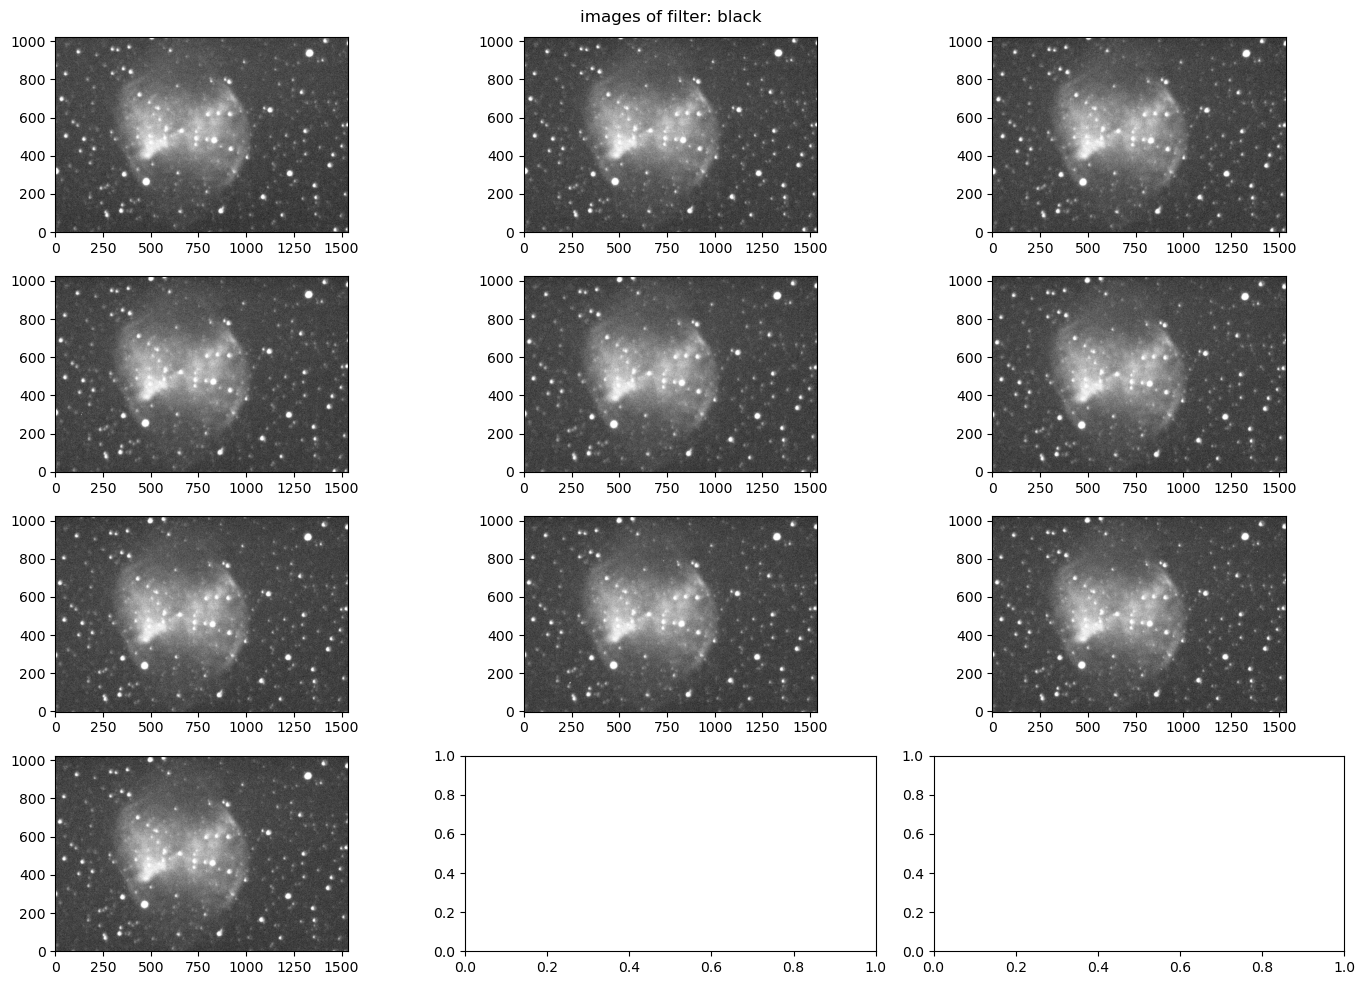

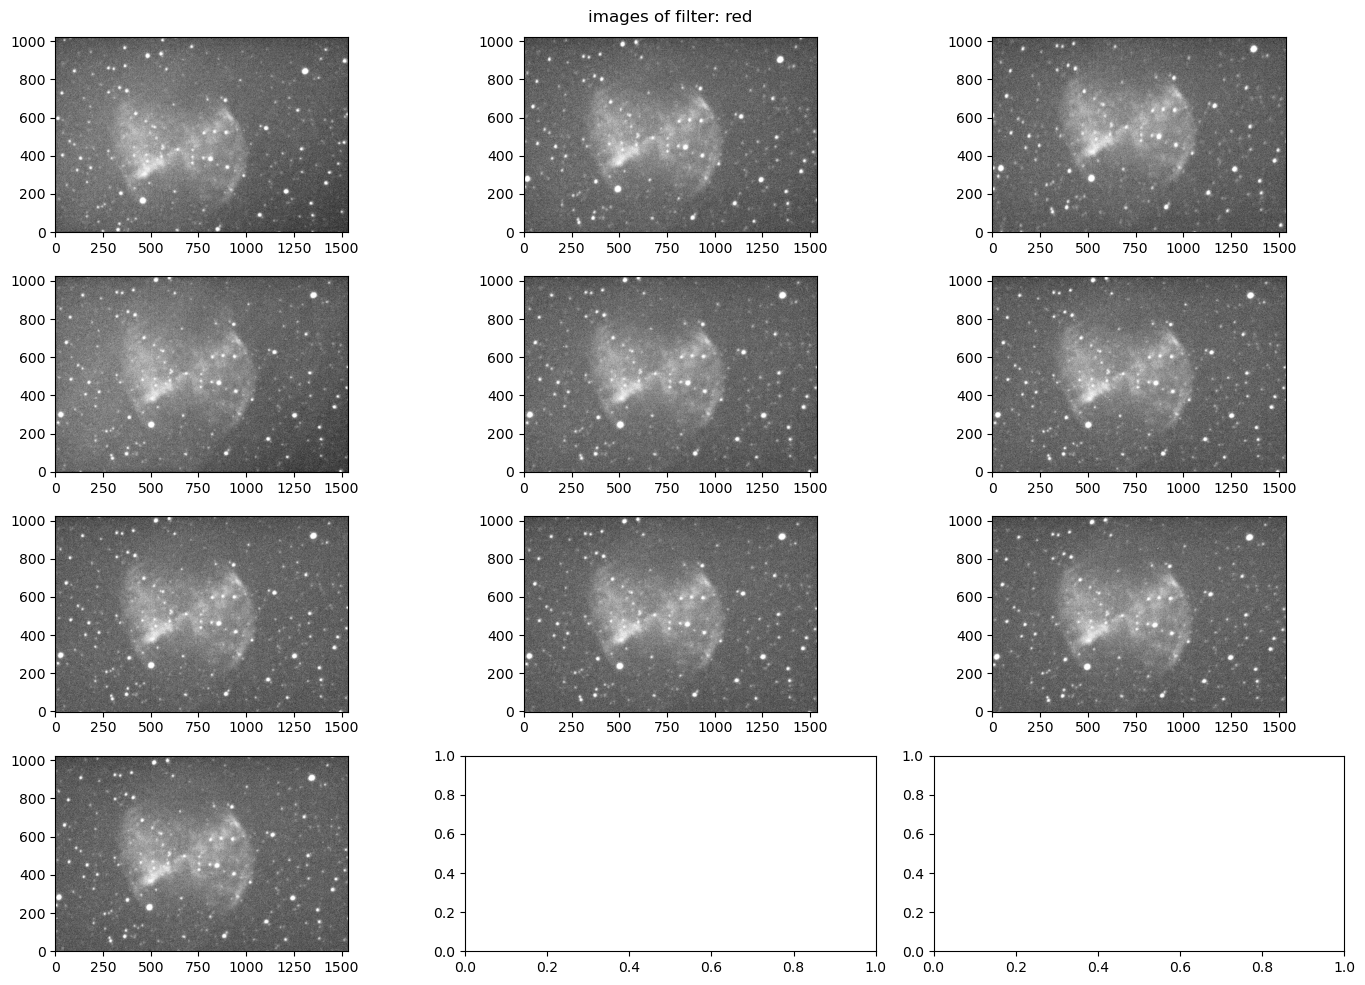

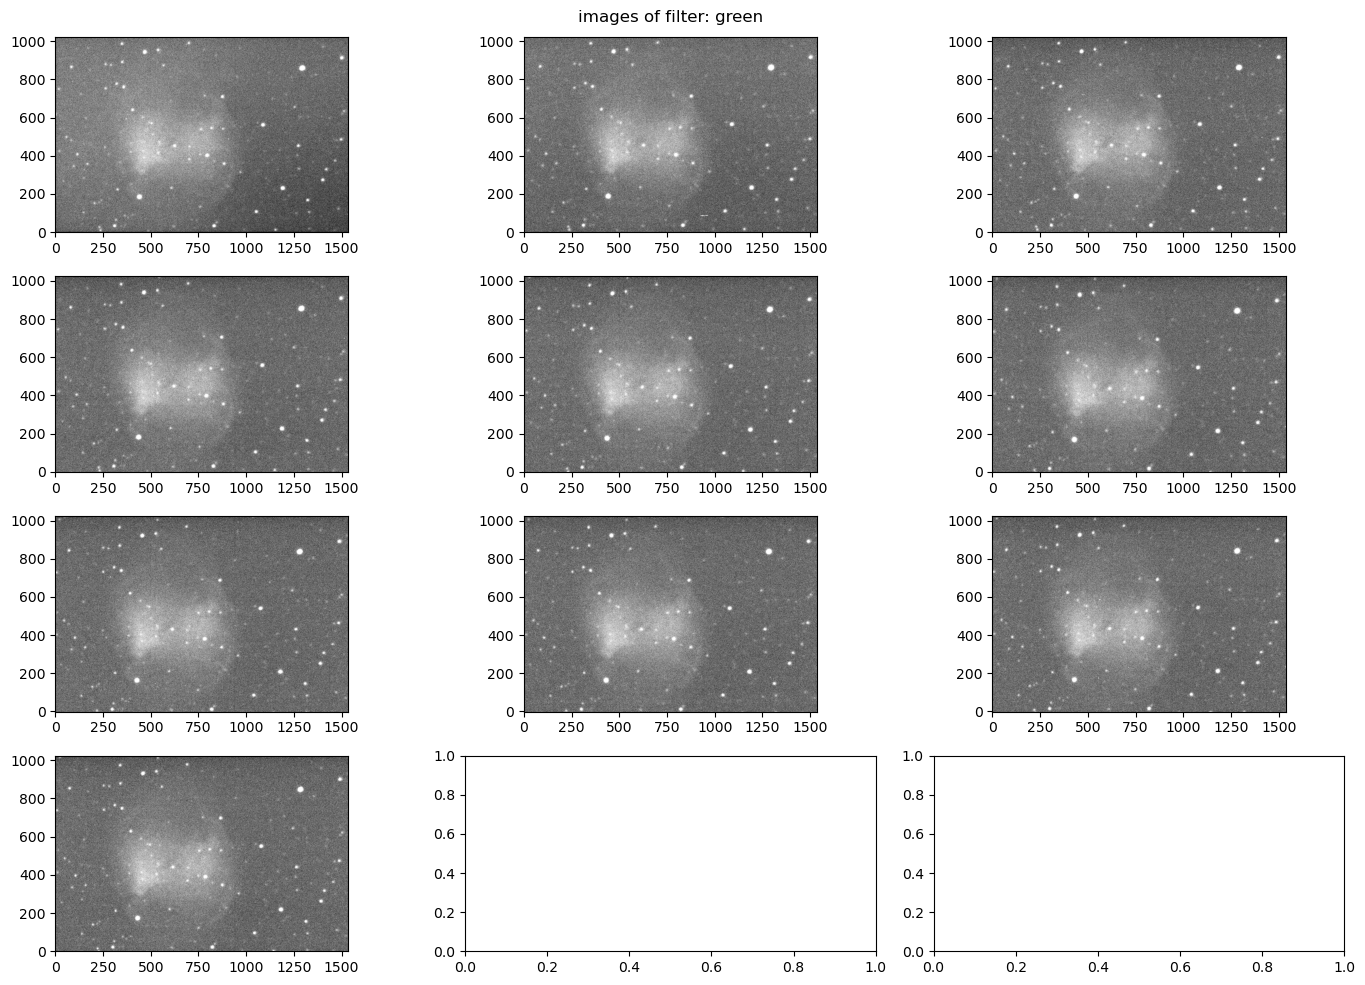

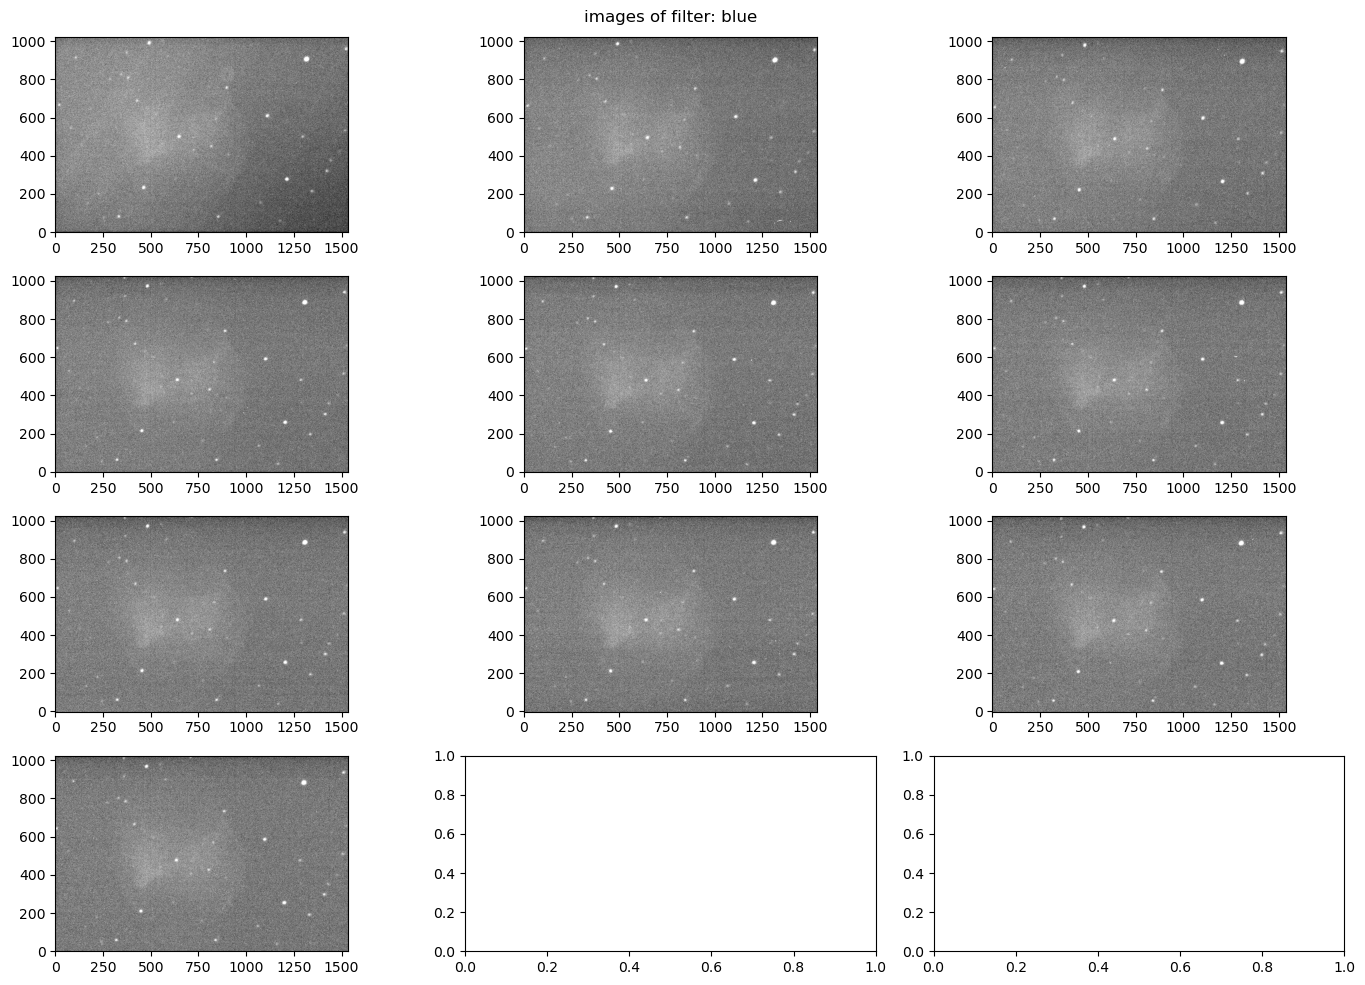

In [5]:
#seperate data in filters into dictionary
dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\m27"
filters = ["black","red","green","blue"]

data = {}
for filter in filters:
    data[filter] = []

for filter in filters:
    files = os.listdir(dir + r"\\" + filter)
    for file in files:
        if "calibrated" in file:
            data[filter].append(fits.open(dir + r"\\" + filter + r"\\" + file))



for filter in filters:
    l = len(data[filter]) / 3
    if l % 3 != 0:
        l = int(l) + 1 
    else:
        l=int(l)
    fig,axs = plt.subplots(l,3,figsize = (14,10))
    for i in range(len(data[filter])):
        m = int(i/3)
        n = i - 3* int(i/3)
        image = data[filter][i][0].data
        lo,up = np.percentile(image,1),np.percentile(image,99)
        axs[m][n].imshow(image,cmap='gray',clim=(lo,up),origin="lower")
    fig.suptitle("images of filter: " + filter)
    fig.tight_layout()
    plt.show()

**ALIGN AND STACK IMAGES OF EACH FILTER**

In [6]:
#image alignment and stack as single function
def align_gauss(im1,im2,pos1,pos2,plot=False,return_shift=False):
    #cut subimages from main images
    subim1 = im1[pos1[1]-30:pos1[1]+30,pos1[0]-30:pos1[0]+30]
    subim2 = im2[pos2[1]-30:pos2[1]+30,pos2[0]-30:pos2[0]+30]

    if plot == True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        lo,up = np.percentile(im1,1),np.percentile(im1,99)
        axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
        axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
        axs[0].set_title("image1")
        lo,up = np.percentile(im2,1),np.percentile(im2,99)
        axs[1].imshow(im2,cmap='gray',clim=(lo,up),origin="lower")
        axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
        axs[1].set_title("image2")
        plt.show()

    #get centers of the object
    center1,center2 = centroid_2dg(subim1)+pos1-[30,30],centroid_2dg(subim2)+pos2-[30,30] #gaussian fit
    if plot==True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        axs[0].imshow(subim1,origin="lower")
        axs[1].imshow(subim2,origin="lower")
        plt.show()

    #apply shift to second image
    im2_subshift = np.roll(im2,-int(np.round(center2[1]-center1[1])),axis=0) #shift in y
    im2_shifted = np.roll(im2_subshift,-int(np.round(center2[0]-center1[0])),axis=1) #shift in x
    im_stacked = (im1 + im2_shifted) /2 #mean in order to keep the illumination time correct

    if plot==True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        lo,up = np.percentile(im1,1),np.percentile(im1,99)
        axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
        axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
        axs[0].set_title("image1")
        lo,up = np.percentile(im2_shifted,1),np.percentile(im2_shifted,99)
        axs[1].imshow(im2_shifted,cmap='gray',clim=(lo,up),origin="lower")
        axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
        axs[1].set_title("image2 shifted")
        plt.show()

        lo,up = np.percentile(im_stacked,1),np.percentile(im_stacked,99)
        plt.imshow(im_stacked,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("stacked images")
        plt.show()

    if return_shift == False:
        return im_stacked #return stacked images
    else:
        return im2_shifted

def align_and_stack_mulitple(images,positions,plot=False):
    im1 = images[0]
    for i in range(len(images)-1):
        im2 = images[i+1]
        if plot == True:
            print(i)
        im1 = align_gauss(im1,im2,positions[0],positions[i+1],plot=plot)
    return im1
        

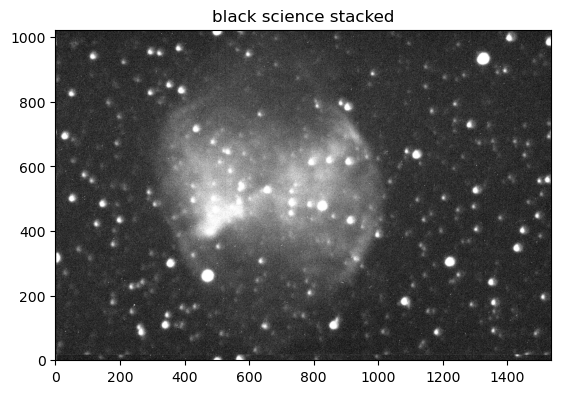

In [7]:
#black filter
filter="black"

if False:
    for i in range(10):
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[800:1000:,1200:1400],cmap='gray',clim=(lo,up),origin="lower")
        plt.grid()
        plt.show()

off_black= (1200,800) #need (x,y) for above functions
positions_black = [(125,130),(125,130),(125,130),(125,125),(125,125),(125,110),(125,110),(125,115),(125,115),(125,115)]
positions_black = [(positions_black[i][0] + off_black[0],positions_black[i][1] + off_black[1]) for i in range(len(positions_black))]

images_black = []
for i in range(10):
    images_black.append(data[filter][i][0].data)

stacked_black = align_and_stack_mulitple(images_black,positions_black,plot=False)

#show result
if True:
        lo,up = np.percentile(stacked_black,1),np.percentile(stacked_black,99)
        plt.imshow(stacked_black,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("black science stacked")
        plt.show()


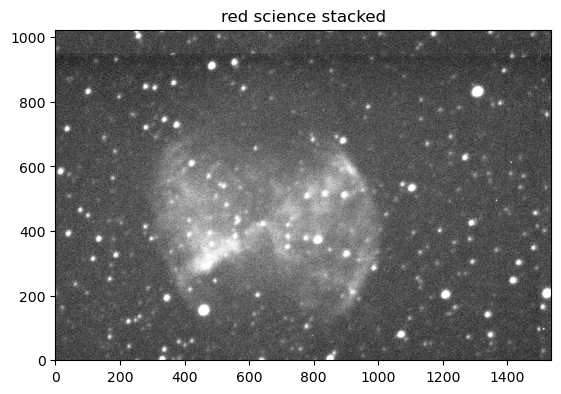

In [8]:
#red filter
filter="red"

#show images
if False:
    for i in range(10):
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[800:1000:,1200:1400],cmap='gray',clim=(lo,up),origin="lower")
        plt.grid()
        plt.show()

#calculate stack
if True:
    off_red= (1200,800) #need (x,y) for above functions
    positions_red = [(110,30),(130,100),(165,155),(150,125),(150,125),(150,125),(150,125),(150,125),(150,115),(150,115)]
    positions_red = [(positions_red[i][0] + off_red[0],positions_red[i][1] + off_red[1]) for i in range(len(positions_red))]

    images_red = []
    for i in range(10):
        images_red.append(data[filter][i][0].data)

    stacked_red = align_and_stack_mulitple(images_red,positions_red,plot=False)

#show result
if True:
        lo,up = np.percentile(stacked_red,1),np.percentile(stacked_red,99)
        plt.imshow(stacked_red,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("red science stacked")
        plt.show()

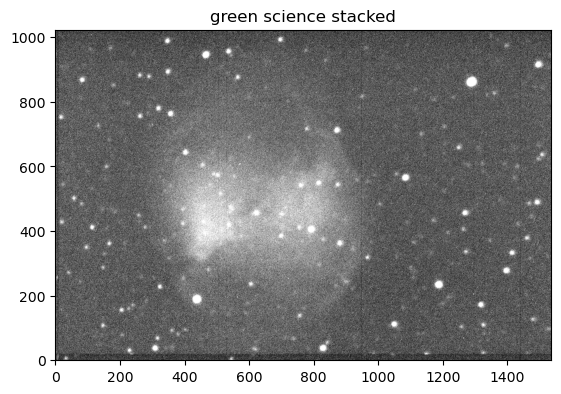

In [9]:
#green filter
filter="green"

#show images
if False:
    for i in range(10):
        print(i)
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[800:1000:,1200:1400],cmap='gray',clim=( lo,up),origin="lower")
        plt.grid()
        plt.show()

#calculate stack
if True:
    off_green= (1200,800) #need (x,y) for above functions
    positions_green = [(85,65),(85,65),(85,65),(85,65),(80,50),(80,45),(75,40),(75,40),(75,45),(75,45)]
    positions_green = [(positions_green[i][0] + off_green[0],positions_green[i][1] + off_green[1]) for i in range(len(positions_green))]

    images_green = []
    for i in range(10):
        images_green.append(data[filter][i][0].data)

    stacked_green = align_and_stack_mulitple(images_green,positions_green,plot=False)

#show result
if True:
        lo,up = np.percentile(stacked_green,1),np.percentile(stacked_green,99)
        plt.imshow(stacked_green,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("green science stacked")
        plt.show()

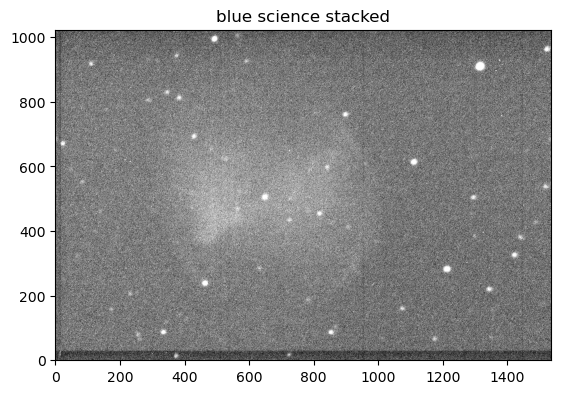

In [10]:
#blue filter
filter="blue"

#show images
if False:
    for i in range(10):
        print(i)
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[800:1000:,1200:1400],cmap='gray',clim=( lo,up),origin="lower")
        plt.grid()
        plt.show()

#calculate stack
if True:
    off_blue= (1200,800) #need (x,y) for above functions
    positions_blue = [(115,110),(115,100),(115,85),(100,85),(100,85),(100,85),(100,85),(100,85),(100,85),(100,85)]
    positions_blue = [(positions_blue[i][0] + off_blue[0],positions_blue[i][1] + off_blue[1]) for i in range(len(positions_blue))]

    images_blue = []
    for i in range(10):
        images_blue.append(data[filter][i][0].data)

    stacked_blue = align_and_stack_mulitple(images_blue,positions_blue,plot=False) #warning is ok fit looks god

#show result
if True:
        lo,up = np.percentile(stacked_blue,1),np.percentile(stacked_blue,99)
        plt.imshow(stacked_blue,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("blue science stacked")
        plt.show()

In [11]:
#save everything in dictionary
stacked_images = {"black":stacked_black,"red":stacked_red,"green":stacked_green,"blue":stacked_blue}

**Background Subtraction**

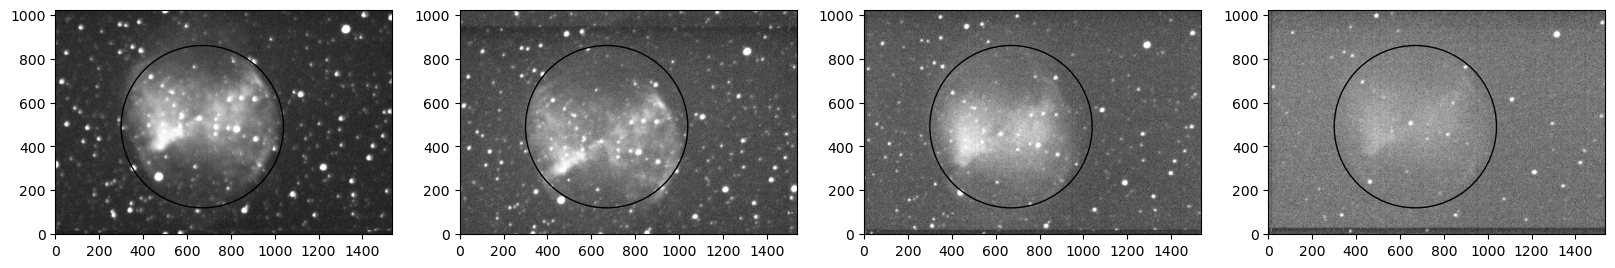

In [12]:
#use circular aperture to ignore background in m27 region

#CROSSCHECK

fig, axs = plt.subplots(1,4,figsize= (20,10))

for i in range(len(filters)):
    image = stacked_images[filters[i]]
    lo,up = np.percentile(image,1),np.percentile(image,99)
    axs[i].imshow(image,cmap='gray',clim=(lo,up),origin="lower")
    m27mask = CircularAperture([670,490],370).plot(axs[i])

plt.show()



In [13]:
#inititalize some necessary instances
sigma_clip = SigmaClip(sigma=3) #object used to cut out outliers out of 3sigma interval
bkg_estimator = MedianBackground() #use the median as backround estimator, could also use the mean
n = 3 #filter size

#create actual mask to ignore background in m27 region

m27mask = CircularAperture([670,490],370).to_mask(method="center").to_image(np.shape(stacked_images["black"]))




#calculate the masks
masks = {}
for filter in filters:
    mask=np.zeros(np.shape(stacked_images[filter]))
    for i in range(len(stacked_images[filter])):
        for j in range(len(stacked_images[filter][i])):
            if master_flats[filter][i][j]<0.2:
                mask[i][j]=1
    mask=mask.astype(bool)
    masks[filter] = mask

#calculate backround for each filter 
bkgs = {}
for filter in filters:
    bkg = Background2D(stacked_images[filter],(50,50),filter_size=(n,n),sigma_clip=sigma_clip, bkg_estimator=bkg_estimator,coverage_mask=masks[filter], mask = m27mask)
    bkgs[filter] = bkg

#subtract background from stacked images
stacked_images_bkgcorr = {}
for filter in filters:
    stacked_images_bkgcorr[filter] = stacked_images[filter] - bkgs[filter].background


#save final images
savename = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\"
if True:
    for filter in filters:
        im = stacked_images_bkgcorr[filter]
        fits.writeto(savename + "final_" +filter+".fits", im, overwrite=True)





In [14]:
#show stacked images, stacked images without backround, background and background_rms
if False:
    for filter in filters:
        fig, axs = plt.subplots(2,2,figsize=(10,6))

        lo,up = np.percentile(stacked_images[filter],1),np.percentile(stacked_images[filter],99)
        axs[0,0].imshow(stacked_images[filter],cmap='gray',clim=(lo,up),origin="lower")
        axs[0,0].set_title("stacked_images")

        lo,up = np.percentile(stacked_images_bkgcorr[filter],1),np.percentile(stacked_images_bkgcorr[filter],99)
        axs[0,1].imshow(stacked_images_bkgcorr[filter],cmap='gray',clim=(lo,up),origin="lower")
        axs[0,1].set_title("background subtracted")

        lo,up = np.percentile(bkgs[filter].background,1),np.percentile(bkgs[filter].background,99)
        axs[1,0].imshow(bkgs[filter].background,cmap='gray',clim=(lo,up),origin="lower")
        axs[1,0].set_title("background")

        lo,up = np.percentile(bkgs[filter].background_rms,1),np.percentile(bkgs[filter].background_rms,99)
        axs[1,1].imshow(bkgs[filter].background_rms,cmap='gray',clim=(lo,up),origin="lower")
        axs[1,1].set_title("background_rms")

        fig.suptitle(filter)

        plt.show()





In [15]:
#make rgb image
#need log scale in order to see anything
def scale_log(channel, vmin=None, vmax=None):
    channel = np.array(channel, dtype=float)
    # log stretch
    scaled = (np.log(channel.clip(vmin, vmax)) - np.log(vmin)) / (np.log(vmax) - np.log(vmin))
    return scaled

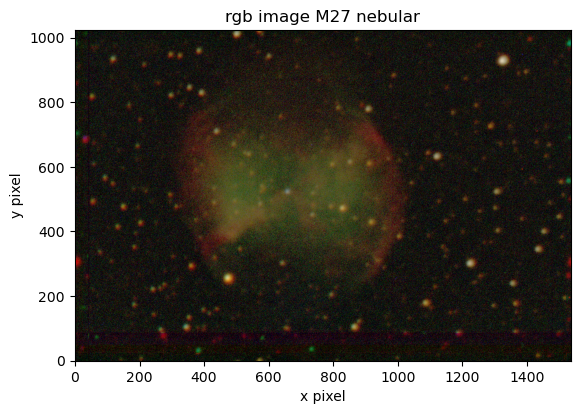

In [17]:
#align different filters:
black = red = stacked_images_bkgcorr["black"]
red = stacked_images_bkgcorr["red"]
green = stacked_images_bkgcorr["green"]
blue = stacked_images_bkgcorr["blue"]

#align everything to black positions

green = align_gauss(black,green,positions_black[0],positions_green[0],plot=False,return_shift=True)
red = align_gauss(black,red,positions_black[0],positions_red[0],plot=False,return_shift=True)
blue = align_gauss(black,blue,positions_black[0],positions_blue[0],plot=False,return_shift=True)
shifted = {"red":red,"green":green,"blue":blue}

savename = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\"
for filter in ["red","green","blue"]:
    fits.writeto(savename + "final_aligned_" + filter + ".fits", shifted[filter], overwrite=True)

#set negatives to zero
def delete_neg(im):
    for i in range(len(im)):
        for j in range(len(im[0])):
            if im[i][j] < 1 :
                im[i][j] = 1
    return im

#check mean in a region without stars
if False:
        lo,up = np.percentile(red,1),np.percentile(red,99)
        plt.imshow(red,cmap='gray',clim=(lo,up),origin="lower")
        plt.plot([1000,1000,1100,1100,1000],[700,800,800,700,700])
        plt.show()

        print(np.mean(red[700:800,1000:1100]))
        print(np.mean(red[800:900,1000:1100]))
    


#set negative values to 1
if True:
    red = delete_neg(red)
    green = delete_neg(green)
    blue = delete_neg(blue)
    black = delete_neg(black)



vmin = min([red.min(),green.min(),blue.min()])
vmax = min([red.max(),green.max(),blue.max()])

red = scale_log(red,vmin=vmin,vmax=vmax)
green = scale_log(green,vmin=vmin,vmax=vmax)
blue = scale_log(blue,vmin=vmin,vmax=vmax)
black = scale_log(black,vmin=vmin,vmax=vmax)

#stack to actual rgb image and show
rgb_image = np.dstack((red, green, blue))
plt.imshow(rgb_image,origin = "lower")

plt.title("rgb image M27 nebular")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
#plt.savefig("m27_rgb_image.png")
plt.show()

